# Agreement networks and maps

Roadmap step 2, part 3. The member-level view: do members cluster by political group without being told their group, which groups sit next to each other, and what separates them?

Same methods as the [USA notebook 02](../../../../usa/pipeline/polarization_clustering/notebooks/02_agreement_networks.ipynb) and [03](../../../../usa/pipeline/polarization_clustering/notebooks/03_embeddings_factions.ipynb):

- **Agreement** between two members is the share of contested roll calls they both voted For or Against on where they voted the same way. Pairs sharing fewer than 20 such votes get no edge. Abstentions aren't used here, unlike notebooks 01 and 02.
- **Group modularity** measures how strongly the political groups organise the agreement network, raw and adjusted for group sizes (modularity over its maximum, Newman's assortativity).
- **Louvain** finds communities without group labels, with 5 seeds. Agreement with the groups is the adjusted Rand index (ARI), over members of a group.
- **Maps** use classical multidimensional scaling of 1 − agreement, fitted separately in each term. They show positions within a term only: the two terms aren't on a common scale and aren't compared.

Each member gets the group they sat in for most of their roll calls in the term. Members who changed group are counted below.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from howtheyvote import load_rollcalls, load_votes

SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical slots 1 to 3
NEUTRAL = "#52514e"
MUTED = "#c9c8c1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})

TERMS = [9, 10]
CUTOFFS = [0.0, 0.025, 0.10]
# Display order: group means on the first dimension of the agreement maps (notebook 03), the same in both terms.
# Non-attached members aren't a group and come last.
GROUP_ORDER = ["GREEN_EFA", "GUE_NGL", "SD", "RENEW", "EPP", "ECR", "ID", "PFE", "ESN", "NI"]
LABELS = {"GUE_NGL": "The Left", "GREEN_EFA": "Greens/EFA", "SD": "S&D", "RENEW": "Renew", "EPP": "EPP",
          "ECR": "ECR", "ID": "ID", "PFE": "PfE", "ESN": "ESN", "NI": "Non-attached"}
BREXIT = pd.Timestamp("2020-01-31")
TERM_10_START = pd.Timestamp("2024-07-16")


def half_year(dates):
    """Half-years as numbers: 2019.5 is July to December 2019, 2020.0 January to June 2020."""
    return dates.dt.year + (dates.dt.month > 6) * 0.5


def half_label(value):
    return f"{int(value)} {'H2' if value % 1 else 'H1'}"


rollcalls = load_rollcalls()
rollcalls = rollcalls[~rollcalls["is_secret"]].set_index("vote_id")
rollcalls["half"] = half_year(rollcalls["date"])

from sklearn.metrics import adjusted_rand_score
from howtheyvote import build_matrix
from clustering import (
    NON_ATTACHED, agreement_graph, agreement_matrix, best_partition, classical_mds, modal_group,
    normalized_modularity, orient, partition_modularity, permuted_matrix, winning_side,
)

NULL_DRAWS = 3
runs, kept = [], {}
for term in TERMS:
    votes = load_votes(term)
    term_rollcalls = rollcalls[rollcalls["term"] == term].reset_index()
    info = modal_group(votes)
    for cutoff in CUTOFFS:
        matrix = build_matrix(votes, term_rollcalls, min_minority_share=cutoff)
        groups = info["group"].reindex(matrix.index)
        agreement = agreement_matrix(matrix)
        graph = agreement_graph(agreement)
        best, labels, stability = best_partition(graph, range(5))
        member = groups != NON_ATTACHED
        sizes = labels.value_counts(normalize=True)
        # Group measures leave out non-attached members, who aren't a group.
        grouped = groups.index[groups != NON_ATTACHED]
        group_graph = graph.subgraph(grouped)
        values = agreement.loc[grouped, grouped].to_numpy()
        same = groups[grouped].to_numpy()[:, None] == groups[grouped].to_numpy()[None, :]
        row = {
            "term": term, "cutoff": cutoff, "members": len(matrix), "rollcalls": matrix.shape[1],
            "within_group_agreement": np.nanmean(np.where(same, values, np.nan)),
            "between_group_agreement": np.nanmean(np.where(~same, values, np.nan)),
            "missing_pairs": (agreement.isna().to_numpy().sum() - len(agreement)) / (len(agreement) * (len(agreement) - 1)),
            "group_modularity": partition_modularity(group_graph, groups[grouped]),
            "group_assortativity": normalized_modularity(group_graph, groups[grouped]),
            "best_modularity": best, "seed_stability": stability,
            "large_communities": int((sizes >= 0.05).sum()),
            "group_ari": adjusted_rand_score(groups[member], labels[member]),
        }
        if cutoff == 0.025:
            nulls = []
            for draw in range(NULL_DRAWS):
                shuffled = permuted_matrix(matrix, np.random.default_rng(draw))
                null_graph = agreement_graph(agreement_matrix(shuffled)).subgraph(grouped)
                nulls.append(normalized_modularity(null_graph, groups[grouped]))
            row["null_assortativity"] = float(np.mean(nulls))
            kept[term] = {"matrix": matrix, "info": info.reindex(matrix.index), "agreement": agreement,
                          "graph": graph, "labels": labels}
        runs.append(row)
    del votes
runs = pd.DataFrame(runs)
print("Members in the matrices who sat in more than one group during the term (by vote rows):",
      {term: int((kept[term]["info"]["groups_held"] > 1).sum()) for term in TERMS})
display(runs.round(3))

Members in the matrices who sat in more than one group during the term (by vote rows): {9: 79, 10: 21}


,term,cutoff,members,rollcalls,within_group_agreement,between_group_agreement,missing_pairs,group_modularity,group_assortativity,best_modularity,seed_stability,large_communities,group_ari,null_assortativity
0,9,0.000,866,19275,0.917,0.642,0.036,0.043,0.053,0.078,1.0,3,0.426,NaN
1,9,0.025,866,17936,0.912,0.618,0.036,0.047,0.058,0.086,1.0,2,0.302,-0.001
2,9,0.100,866,14788,0.902,0.569,0.037,0.059,0.073,0.107,1.0,2,0.302,NaN
3,10,0.000,741,6411,0.922,0.583,0.003,0.053,0.065,0.117,1.0,3,0.482,NaN
4,10,0.025,741,6226,0.920,0.571,0.003,0.056,0.069,0.122,1.0,3,0.482,-0.001
5,10,0.100,741,5793,0.916,0.550,0.004,0.061,0.075,0.134,1.0,3,0.482,NaN


**What this shows**

- **Groups organise the network far beyond chance.** Group modularity adjusted for group sizes, over members of a group, is 0.058 in the 9th term and 0.069 in the 10th. For shuffled votes it is about 0 (−0.001).
- **Members agree more inside their group than across groups:** 91% against 62% of shared votes in the 9th term, and 92% against 57% in the 10th. The absolute modularity values are low because members of different groups still agree on most contested roll calls.
- **Not compared with the USA.** The size-adjusted modularity depends on the number of groups as well as on how separated they are, so a value for eight groups can't be set against the USA's two parties.
- **Louvain is fully stable across seeds** (adjusted Rand index 1.0 between runs). Its communities match the groups only partly (0.30 and 0.48), because they merge neighbouring groups into blocs (below).
- **The cutoff changes little.** Modularity rises slightly with the cutoff, and keeping every roll call (0%) gives a third community in the 9th term.
- **Missing pairs:** 3.6% of member pairs in the 9th term share fewer than 20 votes, mostly UK members and those who took their seats after Brexit, against 0.3% in the 10th.
- **Group changes:** among members in these matrices, 79 in the 9th term and 21 in the 10th voted in more than one group. Each is counted in the group they sat in for most roll calls. The entity docs count 100 and 21 from all group spells, including members with too few votes for the matrix.

## Louvain communities against political groups

Members of each group in each community, at the 2.5% cutoff and resolution 1.

In [2]:
for term in TERMS:
    data = kept[term]
    table = pd.crosstab(data["labels"].rename("community"), data["info"]["group"])
    table = table[[g for g in GROUP_ORDER if g in table.columns]].rename(columns=LABELS)
    print(f"{term}th term")
    display(table)

9th term


group,Greens/EFA,The Left,S&D,Renew,EPP,ECR,ID,Non-attached
community,,,,,,,,
0,92,46,175,100,4,0,0,17
1,0,0,0,27,201,74,79,51


10th term


group,Greens/EFA,The Left,S&D,Renew,EPP,ECR,PfE,ESN,Non-attached
community,,,,,,,,,
0,54,48,138,73,3,0,0,0,6
1,0,0,0,0,10,79,90,27,25
2,0,0,0,3,184,0,1,0,0


**At resolution 1:**

- **9th term: two blocs.** One holds Greens/EFA, The Left, S&D and 100 of 127 Renew members. The other holds 201 of 205 EPP members with ECR, ID and 27 Renew members.
- **10th term: three blocs, with the EPP on its own.**
  - Greens/EFA, The Left, S&D and 73 of 76 Renew members.
  - The EPP, 184 of 197 members.
  - ECR, PfE and ESN, with 10 EPP members.

On a complete network with positive weights, Louvain tends to produce two halves (see the USA notebook). So the number of communities depends on the resolution. The resolution test below shows which differences hold.

In [3]:
resolutions = []
for term in TERMS:
    data = kept[term]
    member = data["info"]["group"] != NON_ATTACHED
    for resolution in [0.9, 1.0, 1.05, 1.1, 1.2]:
        best, labels, stability = best_partition(data["graph"], range(3), resolution)
        sizes = labels.value_counts(normalize=True)
        resolutions.append({
            "term": term, "resolution": resolution, "communities": labels.nunique(),
            "large_communities": int((sizes >= 0.05).sum()), "seed_stability": stability,
            "group_ari": adjusted_rand_score(data["info"]["group"][member], labels[member]),
        })
display(pd.DataFrame(resolutions).round(3))
for term in TERMS:
    for resolution in [0.9, 1.05, 1.1]:
        data = kept[term]
        _, labels, _ = best_partition(data["graph"], range(3), resolution)
        table = pd.crosstab(labels.rename("community"), data["info"]["group"])
        table = table[[g for g in GROUP_ORDER if g in table.columns]].rename(columns=LABELS)
        print(f"{term}th term at resolution {resolution}, communities of at least 5% of members:")
        display(table[table.sum(axis=1) >= 0.05 * len(labels)])

,term,resolution,communities,large_communities,seed_stability,group_ari
0,9,0.90,2,2,0.991,0.311
1,9,1.00,2,2,1.000,0.302
2,9,1.05,5,4,1.000,0.567
3,9,1.10,9,4,1.000,0.603
4,9,1.20,58,5,0.921,0.497
5,10,0.90,2,2,0.989,0.215
6,10,1.00,3,3,1.000,0.482
7,10,1.05,4,3,1.000,0.488
8,10,1.10,6,3,1.000,0.495
9,10,1.20,48,4,0.979,0.353


9th term at resolution 0.9, communities of at least 5% of members:


group,Greens/EFA,The Left,S&D,Renew,EPP,ECR,ID,Non-attached
community,,,,,,,,
0,92,46,175,118,7,0,0,18
1,0,0,0,9,198,74,79,50


9th term at resolution 1.05, communities of at least 5% of members:


group,Greens/EFA,The Left,S&D,Renew,EPP,ECR,ID,Non-attached
community,,,,,,,,
0,92,46,174,19,1,0,0,16
1,0,0,0,1,6,74,79,51
2,0,0,0,10,191,0,0,0
3,0,0,1,96,7,0,0,1


9th term at resolution 1.1, communities of at least 5% of members:


... (3 outputs left out)

10th term at resolution 1.05, communities of at least 5% of members:


group,Greens/EFA,The Left,S&D,Renew,EPP,ECR,PfE,ESN,Non-attached
community,,,,,,,,,
0,54,48,138,71,2,0,0,0,6
1,0,0,0,0,10,79,90,27,25
2,0,0,0,3,185,0,1,0,0


10th term at resolution 1.1, communities of at least 5% of members:


group,Greens/EFA,The Left,S&D,Renew,EPP,ECR,PfE,ESN,Non-attached
community,,,,,,,,,
0,54,48,138,61,2,0,0,0,6
1,0,0,0,0,10,79,90,27,24
2,0,0,0,0,183,0,1,0,0


**What holds across resolutions**

- **In the 10th term the EPP never joins ECR, PfE and ESN.**
  - At 0.9 it joins Greens/EFA, The Left, S&D and Renew (186 of 197).
  - From 1.0 to 1.1 it is a community of its own.
- **In the 9th term the EPP sits with ECR and ID at 0.9 and 1.0** (198 and 201 of 205).
  - From 1.05 it separates, and Renew becomes its own community too.
  - Matching with the groups rises to 0.57 to 0.60.
- **Renew stays with S&D in the 10th term:** 71 to 76 of its 76 members from 0.9 to 1.05. At 1.1, 61 remain in that bloc and the rest fall into small communities.
- By 1.2 both terms break into 48 to 58 communities, mostly tiny.

So "two blocs against three" depends on the resolution. What is robust is which bloc the EPP is grouped with: the right-hand groups in the 9th term at the lower resolutions, never in the 10th.

## Maps of each term

Classical multidimensional scaling of 1 − agreement. The first dimension is oriented so The Left has the lower mean, the second so the EPP has the higher mean; signs are otherwise arbitrary. Each panel highlights one group over all members in grey.

In [4]:
maps, shares = {}, {}
for term in TERMS:
    data = kept[term]
    coordinates, share = classical_mds(data["agreement"], dimensions=3)
    coordinates = orient(coordinates, data["info"]["group"], low="GUE_NGL", column="dim1")
    if coordinates.loc[data["info"]["group"].eq("EPP"), "dim2"].mean() < 0:
        coordinates["dim2"] = -coordinates["dim2"]
    maps[term] = coordinates.join(data["info"])
    shares[term] = share
print("Share of positive eigenvalue mass by dimension:")
display(pd.DataFrame({f"{term}th term": shares[term][:5] for term in TERMS},
                     index=[f"dim{i + 1}" for i in range(5)]).round(3))
for term in TERMS:
    means = maps[term].groupby("group")[["dim1", "dim2", "dim3"]].mean()
    print(f"{term}th term, group means:")
    display(means.reindex([g for g in GROUP_ORDER if g in means.index]).rename(index=LABELS).round(3))

Share of positive eigenvalue mass by dimension:


,9th term,10th term
dim1,0.383,0.610
dim2,0.131,0.143
dim3,0.073,0.022
dim4,0.043,0.016
dim5,0.029,0.014


9th term, group means:


,dim1,dim2,dim3
group,,,
Greens/EFA,-0.260,-0.115,0.029
The Left,-0.239,-0.261,0.079
S&D,-0.196,0.002,-0.000
Renew,-0.100,0.063,-0.036
EPP,0.044,0.138,-0.044
ECR,0.331,0.079,0.048
ID,0.417,-0.117,0.095
Non-attached,0.227,-0.159,-0.053


10th term, group means:


,dim1,dim2,dim3
group,,,
Greens/EFA,-0.322,-0.093,0.035
The Left,-0.295,-0.295,-0.023
S&D,-0.254,-0.003,0.016
Renew,-0.182,0.065,-0.010
EPP,-0.063,0.131,-0.021
ECR,0.380,0.094,0.045
PfE,0.468,-0.065,-0.009
ESN,0.517,-0.112,-0.065
Non-attached,0.205,-0.311,0.028


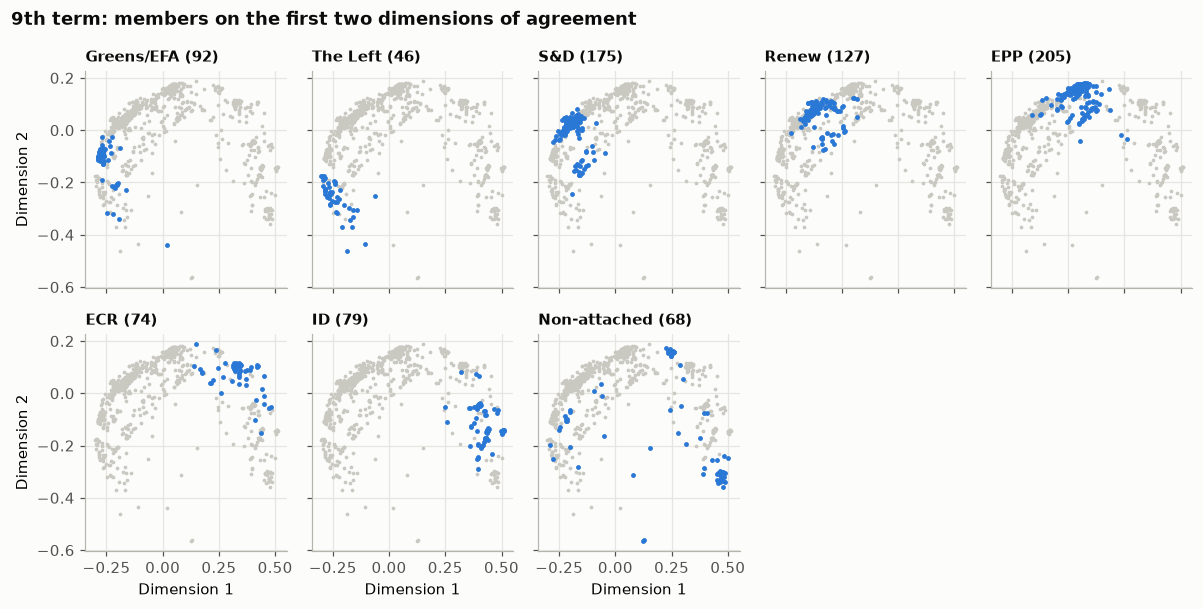

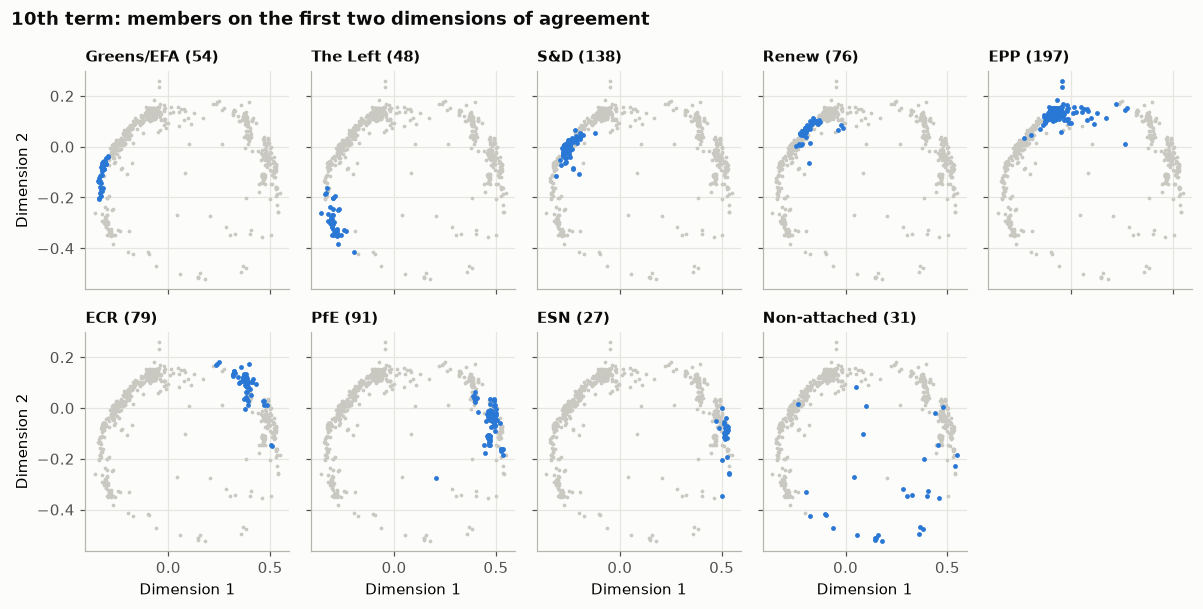

In [5]:
for term in TERMS:
    data = maps[term]
    shown = [g for g in GROUP_ORDER if g in set(data["group"])]
    columns = 5
    rows = int(np.ceil(len(shown) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(11, 2.5 * rows + 0.6), sharex=True, sharey=True)
    for axis, group in zip(axes.flat, shown):
        axis.scatter(data["dim1"], data["dim2"], s=6, color=MUTED, linewidth=0)
        members = data[data["group"] == group]
        axis.scatter(members["dim1"], members["dim2"], s=10, color=SERIES[0], linewidth=0)
        axis.set_title(f"{LABELS[group]} ({len(members)})", fontsize=10)
    for axis in axes.flat[len(shown):]:
        axis.set_visible(False)
    for axis in axes[-1]:
        axis.set_xlabel("Dimension 1")
    for axis in axes[:, 0]:
        axis.set_ylabel("Dimension 2")
    fig.suptitle(f"{term}th term: members on the first two dimensions of agreement", x=0.01, ha="left",
                 fontweight="bold")
    fig.tight_layout()
    plt.show()

**What this shows**

- **Both terms show one ordering:** Greens/EFA and The Left at one end, then S&D, Renew, the EPP and ECR, then ID (9th term) or PfE and ESN (10th) at the other.
- **Groups occupy compact, separate stretches of it.** In the 10th term there is a visible gap between the EPP and ECR, with few members between them.
- **Non-attached members are spread out** (see below).
- **Eigenvalue mass:** the first dimension holds 38% of the positive mass in the 9th term and 61% in the 10th, and the second 13% to 14%. These are fitted separately on different roll calls and aren't compared between terms.

### Is the second dimension a horseshoe?

Both maps bend into an arch. Classical scaling produces this shape when members lie along a single ordering and agreement between far-apart members stops falling ([Diaconis, Goel and Holmes 2008](https://arxiv.org/abs/0811.1477), confirmed source). Then the second dimension is largely a curved function of the first, not a separate pattern. The check: how much of dimension 2 a quadratic in dimension 1 explains, and whether the rest still relates to anything.

In [6]:
from numpy.polynomial import polynomial

for term in TERMS:
    data = maps[term]
    coefficients = polynomial.polyfit(data["dim1"], data["dim2"], 2)
    fitted = polynomial.polyval(data["dim1"], coefficients)
    residual = data["dim2"] - fitted
    r_squared = 1 - residual.var() / data["dim2"].var()
    maps[term]["dim2_residual"] = residual
    print(f"{term}th term: a quadratic in dimension 1 explains {r_squared:.1%} of dimension 2")

9th term: a quadratic in dimension 1 explains 48.6% of dimension 2
10th term: a quadratic in dimension 1 explains 33.7% of dimension 2


**The second dimension is partly a curve in the first.** A quadratic in dimension 1 explains 49% of dimension 2 in the 9th term and 34% in the 10th. The arch can't tell an artefact apart from a real pattern that separates the centre from both ends. What remains after removing the curve still relates weakly to how often members win (Spearman 0.24 and 0.23, below). So the second dimension isn't interpreted here, and the maps are read for their main ordering.

### The 9th term without the UK

3.6% of member pairs in the 9th term share fewer than 20 votes, mostly UK members and those who took their seats after Brexit. Classical scaling fills those distances with the mean, which could add structure. Refitting on roll calls after 31 January 2020 only, with members who cast at least 20 votes then:

In [7]:
votes = load_votes(9)
after = rollcalls[(rollcalls["term"] == 9) & (rollcalls["date"] > BREXIT)].reset_index()
matrix = build_matrix(votes[votes["vote_id"].isin(after["vote_id"])], after)
agreement = agreement_matrix(matrix)
coordinates, share = classical_mds(agreement, dimensions=3)
groups = modal_group(votes).reindex(matrix.index)["group"]
coordinates = orient(coordinates, groups, low="GUE_NGL", column="dim1")
print(f"{len(matrix)} members, {matrix.shape[1]} roll calls; pairs without an edge: "
      f"{(agreement.isna().to_numpy().sum() - len(agreement)) / (len(agreement) * (len(agreement) - 1)):.2%}")
print("Share of positive eigenvalue mass, after Brexit:", share[:5].round(3), "| whole term:", shares[9][:5].round(3))
means = coordinates.join(groups).groupby("group")["dim1"].mean()
print("Group means on dimension 1, after Brexit:")
display(means.reindex([g for g in GROUP_ORDER if g in means.index]).rename(index=LABELS).round(3).to_frame().T)
del votes

787 members, 17203 roll calls; pairs without an edge: 1.29%
Share of positive eigenvalue mass, after Brexit: [0.456 0.149 0.051 0.03  0.024] | whole term: [0.383 0.131 0.073 0.043 0.029]
Group means on dimension 1, after Brexit:


group,Greens/EFA,The Left,S&D,Renew,EPP,ECR,ID,Non-attached
dim1,-0.267,-0.257,-0.182,-0.088,0.065,0.354,0.408,0.054


**The ordering doesn't come from the filled-in distances.** After Brexit, missing pairs fall to 1.3%. The first dimension's share rises to 46%, and the group order on it is the same. The non-attached mean moves towards the centre (0.054, from 0.227), mainly because the UK's non-attached members left. The whole-term map is kept as the main one.

## What the dimensions track

The dimensions are summaries of who votes with whom, not measured beliefs. To describe them in terms of behaviour, each member's coordinates are compared with how often they were on the winning side of contested roll calls (For or Against matching the winning side, out of their For and Against votes), and with how often they voted For. Spearman correlations across members, within each term.

In [8]:
behaviour = {}
for term in TERMS:
    matrix = kept[term]["matrix"]
    side = winning_side(rollcalls.loc[matrix.columns]).map({"FOR": 1.0, "AGAINST": -1.0}).astype("float64")
    values = matrix.to_numpy(dtype="float64")
    won = (values == side.to_numpy()[None, :]) & ~np.isnan(values)
    cast = ~np.isnan(values) & ~np.isnan(side.to_numpy()[None, :])
    frame = pd.DataFrame({
        "winning_side_rate": won.sum(axis=1) / cast.sum(axis=1),
        "for_rate": (values == 1).sum(axis=1) / (~np.isnan(values)).sum(axis=1),
    }, index=matrix.index)
    behaviour[term] = maps[term].join(frame)
correlations = pd.concat({
    f"{term}th term": behaviour[term][["dim1", "dim2", "dim2_residual", "dim3", "winning_side_rate", "for_rate"]]
    .corr(method="spearman").loc[["dim1", "dim2", "dim2_residual", "dim3"], ["winning_side_rate", "for_rate"]]
    for term in TERMS
}, axis=1)
display(correlations.round(3))
for term in TERMS:
    by_group = behaviour[term].groupby("group")[["winning_side_rate", "for_rate"]].mean()
    print(f"{term}th term, group means:")
    display(by_group.reindex([g for g in GROUP_ORDER if g in by_group.index]).rename(index=LABELS).round(3))

9th term                  10th term         
              winning_side_rate for_rate winning_side_rate for_rate
dim1                     -0.489   -0.869            -0.409    0.188
dim2                      0.383   -0.306             0.676   -0.621
dim2_residual             0.236   -0.034             0.226   -0.214
dim3                     -0.253    0.122            -0.247    0.520

9th term, group means:


,winning_side_rate,for_rate
group,,
Greens/EFA,0.756,0.660
The Left,0.647,0.649
S&D,0.867,0.619
Renew,0.899,0.555
EPP,0.815,0.536
ECR,0.551,0.489
ID,0.423,0.469
Non-attached,0.508,0.491


10th term, group means:


,winning_side_rate,for_rate
group,,
Greens/EFA,0.753,0.521
The Left,0.609,0.532
S&D,0.845,0.467
Renew,0.892,0.414
EPP,0.905,0.402
ECR,0.512,0.552
PfE,0.395,0.549
ESN,0.325,0.490
Non-attached,0.434,0.578


**What this shows**

- **The ordering isn't a For/Against split.** Its correlation with how often members vote For flips between terms: −0.87 in the 9th, +0.19 in the 10th.
  - In the 9th term the right-hand groups voted For least often.
  - In the 10th, the non-attached members, ECR and PfE vote For most often.
  - Which side proposes what changed, but the ordering didn't.
- **Winning peaks in the centre.** Renew, the EPP and S&D are on the winning side 81% to 91% of the time. Both ends win less, the right-hand end least (ID, PfE and ESN 33% to 42%, The Left 61% to 65%). The negative correlation with dimension 1 (−0.49 and −0.41) mainly reflects that the right-hand end loses more than the left-hand end.
- **The arch carries most of the second dimension's link to winning.** The raw second dimension correlates more strongly with winning (0.38 and 0.68), because the arch puts the centre at the top. Most of that goes once the curve is removed.

This is behaviour on roll calls the groups chose to request. Calling the ordering left and right would need outside measures of the parties' positions, which aren't used here.

## Where non-attached members sit

Each non-attached member's mean agreement with the members of each group, and the group they agree with most.

In [9]:
for term in TERMS:
    data = kept[term]
    groups = data["info"]["group"]
    non_attached = groups.index[groups == NON_ATTACHED]
    mean_agreement = data["agreement"].loc[non_attached].T.groupby(groups).mean().T.drop(columns=NON_ATTACHED)
    nearest = mean_agreement.idxmax(axis=1)
    summary = nearest.map(LABELS).value_counts().rename("non-attached members").to_frame()
    summary["countries"] = nearest.map(LABELS).to_frame("group").join(data["info"]["country"]).groupby("group")[
        "country"].agg(lambda s: ", ".join(sorted(s.unique())))
    print(f"{term}th term: {len(non_attached)} non-attached members (by modal group)")
    display(summary)

9th term: 68 non-attached members (by modal group)


,non-attached members,countries
ID,33,"GBR, GRC, SVK"
ECR,14,"GBR, HRV, HUN, NLD"
Greens/EFA,13,"DEU, ESP, ITA"
The Left,4,"DEU, GRC, HRV"
S&D,2,"HUN, SVK"
Renew,1,LTU
EPP,1,HUN


10th term: 31 non-attached members (by modal group)


,non-attached members,countries
The Left,12,"CYP, DEU, GRC, SVK"
ESN,10,"CZE, DEU, ESP, GRC, LUX, POL, ROU, SVK"
PfE,5,"ROU, SVK"
EPP,2,"BGR, FRA"
Renew,1,BGR
S&D,1,DEU


**Non-attached members aren't a bloc.**

- **9th term:** 33 of 68 vote most like ID, including members from the UK; 14 like ECR; 13 like Greens/EFA (from Germany, Spain and Italy). The rest spread across other groups.
- **10th term:** 12 of 31 vote most like The Left, 10 like ESN and 5 like PfE.

In both terms most non-attached members vote like one of the groups at the two ends of the ordering. They are left out of group-line measures.

## Summary

- **Members cluster by political group without being told their group.** Members agree on 91% to 92% of shared votes inside their group and 57% to 62% across groups. Size-adjusted group modularity is 0.058 and 0.069, against about 0 for shuffled votes.
- **One ordering, from Greens/EFA to ESN, organises both terms,** with or without the UK's members. The second dimension of the maps is partly a curve in the first and isn't interpreted.
- **Louvain's bloc counts depend on the resolution, but the EPP's placement doesn't.**
  - In the 9th term it is grouped with ECR and ID at resolution 1 or below.
  - In the 10th term it is never grouped with ECR, PfE and ESN: it stands alone, or joins S&D and Renew at lower resolution.
- **Members at the centre of the ordering are on the winning side most often.** The right-hand end is on it least.